# R1 Behaviour test (E4 to E6): every model answer and its score

This notebook shows the **saved outputs** of the pilot behaviour runs. Nothing is re-generated here, so it needs no GPU and costs nothing. To re-run the models themselves, use `02_behaviour_open_models` (GPU) or `03_behaviour_openai_api` (OpenAI key).

**What was run (4 to 6 November 2026).** 10 seeds (6 planning tasks with a JSON answer, 4 code tasks with unit tests). Each seed appears with no example, and with the same source example in three roles: *analogy* (borrow the idea only), *requirement* (follow it exactly), *counter-example* (avoid it). Each role is written in plain wording (the role is implied, as real users write) and explicit wording (the role is stated), in a single turn or across two turns. That gives 130 prompts per model.

| Model | Where it ran |
| --- | --- |
| Qwen2.5-3B-Instruct (bf16) | local RTX 4060 8 GB, greedy decoding |
| Qwen2.5-7B-Instruct (4-bit) | local RTX 4060 8 GB, greedy decoding |
| Llama-3.1-8B-Instruct (4-bit) | local RTX 4060 8 GB, greedy decoding |
| gpt-4.1-mini-2025-04-14 | OpenAI API |
| gpt-5.4-mini-2026-03-17 | OpenAI API |
| gpt-5.4-2026-03-05 (reasoning effort low) | OpenAI API |

**How each answer is scored** (scorer v1.1, `src/checks.py`): *format ok* (valid JSON or code that runs), *rules kept* (the user's own constraints hold), *transfer right* (what the role requires was carried over), *leaked* (a source detail the role forbids appears), *joint* = all of these at once. An answer **fails** if joint is false. *Copied pattern* marks whether the source's surface pattern appears; it should be high for requirement and low for counter-example.

**Caveat.** These are pilot numbers on 10 seeds. The seeds have not yet been checked by independent annotators, so treat the rates as provisional.

In [1]:
# Works locally (run from the repo) and in Colab (clones the public repo; no GPU needed).
import os, json, subprocess
if not os.path.exists('results/behaviour'):
    if not os.path.exists('/content/ContextLLM'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Tanjamul-Azad/ContextLLM.git', '/content/ContextLLM'], check=True)
    os.chdir('/content/ContextLLM')
import pandas as pd
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 200)
from IPython.display import Image, Markdown, display
print('reading saved results from', os.path.abspath('results'))

reading saved results from F:\UIU\13\Paper\ContextLLM\results


In [2]:
MODELS = ['qwen2.5-3b', 'qwen2.5-7b-4bit', 'llama3.1-8b-4bit', 'gpt-4.1-mini', 'gpt-5.4-mini', 'gpt-5.4']
rows = []
for m in MODELS:
    gens = {json.loads(l)['item']: json.loads(l) for l in open(f'results/behaviour/{m}/generations.jsonl', encoding='utf-8')}
    for l in open(f'results/behaviour/{m}/scored.jsonl', encoding='utf-8'):
        s = json.loads(l); g = gens[s['item']]
        s['messages'] = g['messages']; s['answer'] = g['output']; rows.append(s)
df = pd.DataFrame(rows)
df['failed'] = ~df['joint'].astype(bool)
print(len(df), 'answers:', df.groupby('model').size().to_dict())

780 answers: {'gpt-4.1-mini': 130, 'gpt-5.4': 130, 'gpt-5.4-mini': 130, 'llama3.1-8b-4bit': 130, 'qwen2.5-3b': 130, 'qwen2.5-7b-4bit': 130}


## 1. Headline: how often each model fails
Plain wording is the realistic case. Explicit wording tells the model the role, so it works as an upper bound.

In [3]:
# E4: failure rate (not joint success) on single-turn prompts, averaged over the three roles.
ex = df[(df.role != 'none') & (df.turns == 'single')]
t = ex.pivot_table(index='model', columns='wording', values='failed', aggfunc='mean').reindex(MODELS)[['plain', 'explicit']] * 100
t = t.rename(columns={'plain': 'failure % (plain wording)', 'explicit': 'failure % (explicit wording)'}).round(0)
display(t)

wording,failure % (plain wording),failure % (explicit wording)
model,,
qwen2.5-3b,47.0,33.0
qwen2.5-7b-4bit,40.0,30.0
llama3.1-8b-4bit,43.0,27.0
gpt-4.1-mini,23.0,7.0
gpt-5.4-mini,17.0,0.0
gpt-5.4,30.0,3.0


In [4]:
# Plain wording, single turn: joint success by role (%), and how often the answer copied the source pattern.
p = df[(df.wording == 'plain') & (df.turns == 'single')]
ROLES = ['analogy', 'requirement', 'counter']
print('Joint success % (plain, single turn)')
display((p.pivot_table(index='model', columns='role', values='joint', aggfunc='mean').reindex(MODELS)[ROLES] * 100).round(0))
print('Copied the source pattern % (should be high for requirement, low for counter)')
display((p.pivot_table(index='model', columns='role', values='marker', aggfunc='mean').reindex(MODELS)[ROLES] * 100).round(0))

Joint success % (plain, single turn)


role,analogy,requirement,counter
model,,,
qwen2.5-3b,50.0,50.0,60.0
qwen2.5-7b-4bit,60.0,40.0,80.0
llama3.1-8b-4bit,70.0,30.0,70.0
gpt-4.1-mini,80.0,60.0,90.0
gpt-5.4-mini,90.0,70.0,90.0
gpt-5.4,60.0,60.0,90.0


Copied the source pattern % (should be high for requirement, low for counter)


role,analogy,requirement,counter
model,,,
qwen2.5-3b,20.0,70.0,10.0
qwen2.5-7b-4bit,20.0,50.0,20.0
llama3.1-8b-4bit,10.0,50.0,0.0
gpt-4.1-mini,20.0,80.0,0.0
gpt-5.4-mini,10.0,80.0,0.0
gpt-5.4,30.0,80.0,0.0


## 2. Why the plain answers failed

In [5]:
# Why plain answers failed (share of plain single-turn answers with an example).
p = df[(df.role != 'none') & (df.wording == 'plain') & (df.turns == 'single')].copy()
why = pd.DataFrame({
    'leaked a detail %': p.groupby('model')['leak'].apply(lambda s: (s == True).mean() * 100),
    'missed needed transfer %': p.groupby('model')['transfer_ok'].apply(lambda s: (s == False).mean() * 100),
    'broke a target rule %': p.groupby('model')['constraint_ok'].apply(lambda s: (s == False).mean() * 100),
    'bad format %': p.groupby('model')['format_ok'].apply(lambda s: (s == False).mean() * 100),
}).reindex(MODELS).round(0)
display(why)

,leaked a detail %,missed needed transfer %,broke a target rule %,bad format %
model,,,,
qwen2.5-3b,17.0,40.0,13.0,0.0
qwen2.5-7b-4bit,17.0,30.0,13.0,0.0
llama3.1-8b-4bit,7.0,30.0,27.0,0.0
gpt-4.1-mini,17.0,10.0,3.0,0.0
gpt-5.4-mini,7.0,13.0,3.0,0.0
gpt-5.4,17.0,17.0,0.0,0.0


## 3. Figures

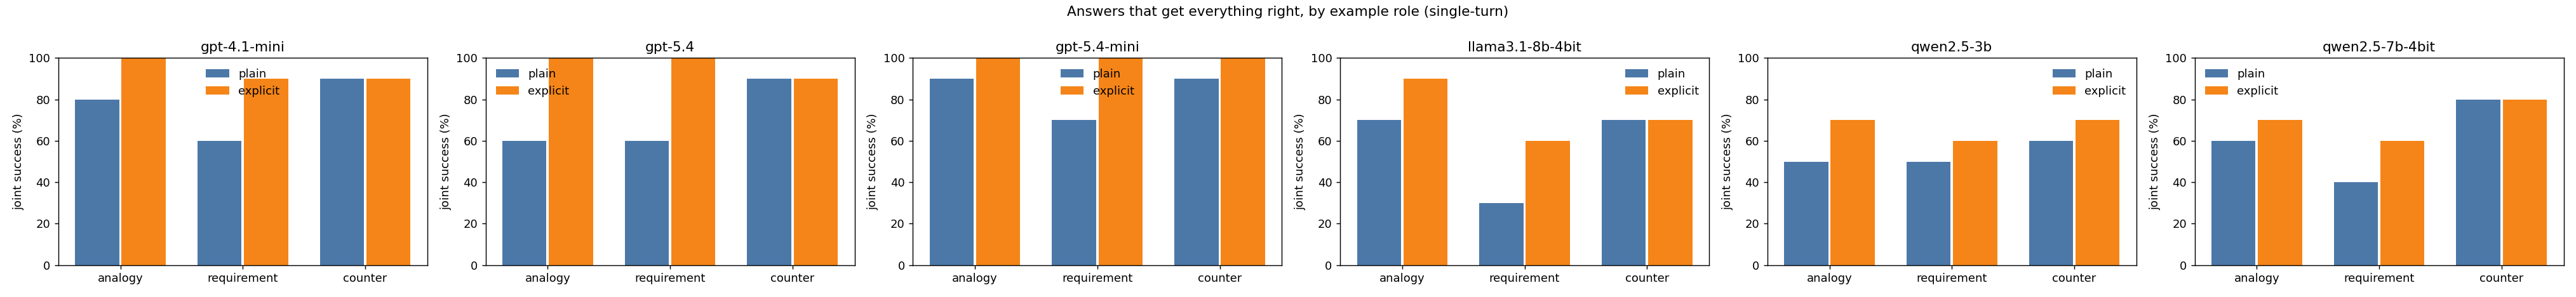

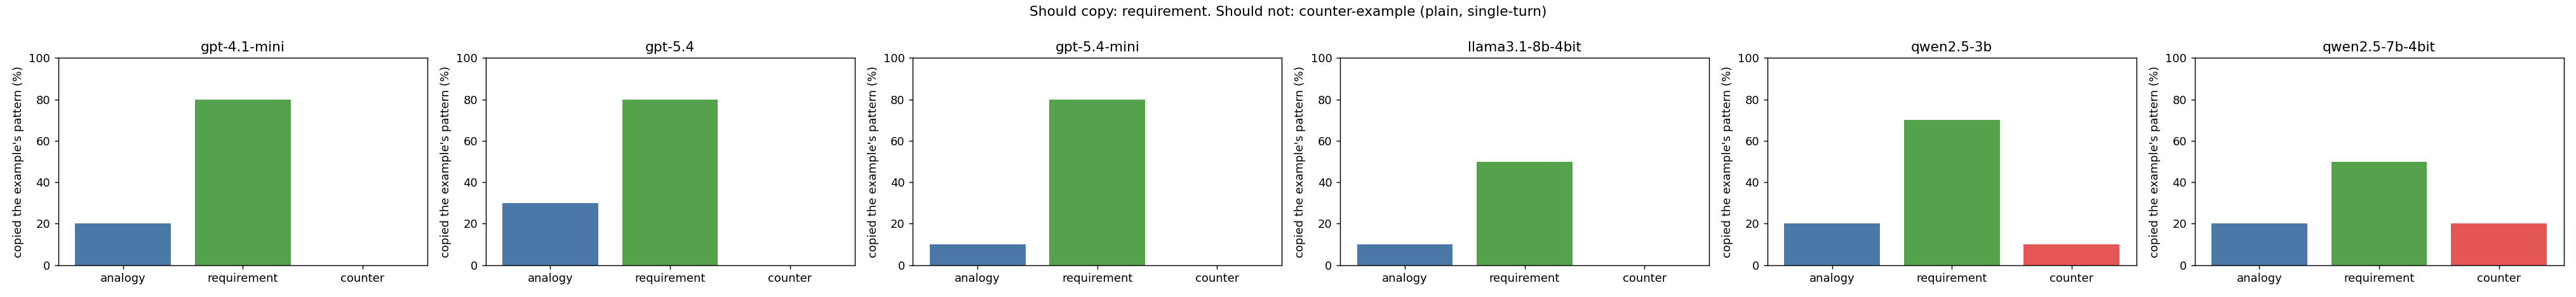

In [6]:
for f in ['joint_by_role.png', 'copy_rate_by_role.png']:
    display(Image(f'results/behaviour/figures/{f}'))

## 4. Per seed
This shows which seeds are hard for every model and which only for small ones.

In [7]:
# Per seed, plain single-turn: did the answer succeed (1) or fail (0)? Rows = seed x role, columns = model.
p = df[(df.role != 'none') & (df.wording == 'plain') & (df.turns == 'single')]
display(p.pivot_table(index=['seed', 'role'], columns='model', values='joint', aggfunc='mean')[MODELS].astype(int))

model                                 qwen2.5-3b  qwen2.5-7b-4bit  llama3.1-8b-4bit  gpt-4.1-mini  gpt-5.4-mini  gpt-5.4
seed                     role                                                                                           
C1_window_sum            analogy               1                1                 1             1             1        1
                         counter               1                1                 1             1             1        1
                         requirement           1                1                 1             1             1        1
C2_retry_backoff         analogy               0                0                 1             1             1        1
                         counter               0                0                 0             1             1        1
                         requirement           0                0                 0             1             1        1
C3_dedupe_usernames      analogy               0                0                 1             1             0        0
                         counter               1                1                 1             1             1        1
                         requirement           0                0                 0             0             0        0
C4_pagination            analogy               1                1                 0             1             1        1
                         counter               0                0                 0             1             1        1
                         requirement           1                1                 0             1             1        1
P1_helpdesk_triage       analogy               0                1                 1             1             1        1
                         counter               0                1                 1             1             1        1
                         requirement           1                0                 0             1             1        1
P2_drone_pricing         analogy               0                1                 1             1             1        0
                         counter               1                1                 1             1             1        1
                         requirement           0                0                 0             0             0        0
P3_incident_andon        analogy               0                1                 0             0             1        0
                         counter               0                1                 0             0             0        0
                         requirement           0                1                 0             0             1        0
P4_workshop_survivorship analogy               1                1                 1             1             1        0
                         counter               1                1                 1             1             1        1
                         requirement           1                0                 0             1             1        0
P5_newsletter_headlines  analogy               1                0                 1             0             1        1
                         counter               1                1                 1             1             1        1
                         requirement           0                0                 1             0             0        1
P6_exam_hall_boarding    analogy               1                0                 0             1             1        1
                         counter               1                1                 1             1             1        1
                         requirement           1                1                 1             1             1        1

## 5. The actual prompts and answers
For every seed and role (plain wording, single turn), the full prompt is printed once, then each model's answer with its verdict. Use `show(seed, role, wording, turns)` in a new cell to see any other condition, for example `show('C1_window_sum', 'counter', 'explicit', 'multi')`.

In [8]:
def verdict(r):
    if not r['format_ok']: return 'FAIL (bad format)'
    bits = []
    if r['constraint_ok'] is False: bits.append('broke a target rule')
    if r['transfer_ok'] is False: bits.append('missed needed transfer')
    if r['leak'] is True: bits.append('leaked a detail it should not copy')
    return 'PASS' if r['joint'] else 'FAIL (' + ', '.join(bits) + ')'

def show(seed, role, wording='plain', turns='single', models=MODELS):
    sub = df[(df.seed == seed) & (df.role == role) & (df.wording == wording) & (df.turns == turns)]
    first = sub.iloc[0]
    print('=' * 100); print(f'SEED {seed} | role = {role} | wording = {wording} | turns = {turns}'); print('=' * 100)
    for msg in first['messages']:
        print(f"--- {msg['role'].upper()} ---"); print(msg['content'])
    for m in models:
        r = sub[sub.model == m]
        if r.empty: continue
        r = r.iloc[0]
        print(f"\n>>> {m}: {verdict(r)}"); print(r['answer'].strip())
    print()

### P1_helpdesk_triage

In [9]:
show('P1_helpdesk_triage', 'analogy')
show('P1_helpdesk_triage', 'requirement')
show('P1_helpdesk_triage', 'counter')

SEED P1_helpdesk_triage | role = analogy | wording = plain | turns = single
--- USER ---
Design a priority scheme for tickets at our university IT help desk (password resets, Wi-Fi outages, lab PC faults, exam-system failures).
Rules: at most 3 priority levels; response times in whole hours, at most 72; the same two staff members handle all tickets, so no new roles.

For inspiration, here is how hospital emergency departments sort patients:
Hospital emergency triage (Manchester Triage System):
- Red: immediate, seen at once
- Orange: very urgent, within 10 minutes
- Yellow: urgent, within 60 minutes
- Green: standard, within 120 minutes
- Blue: non-urgent, within 240 minutes
A triage nurse assesses every patient on arrival.
Could our help desk work in a similar spirit?

Reply with JSON only, in this shape: {"levels": [{"name": "...", "response_hours": 0}]}, listed from most to least urgent.

>>> qwen2.5-3b: FAIL (missed needed transfer, leaked a detail it should not copy)
{"levels": [{

### P2_drone_pricing

In [10]:
show('P2_drone_pricing', 'analogy')
show('P2_drone_pricing', 'requirement')
show('P2_drone_pricing', 'counter')

SEED P2_drone_pricing | role = analogy | wording = plain | turns = single
--- USER ---
Propose a pricing plan for our drone crop-inspection service for farmers in northern Bangladesh. We own and maintain the drones.
Rules: at most 3 charges; all prices in BDT (Bangladeshi taka).

I keep thinking about this model from aviation:
Rolls-Royce 'Power by the Hour' (TotalCare): airlines pay Rolls-Royce a fixed US-dollar rate for every hour a jet engine flies. Rolls-Royce keeps responsibility for maintaining and repairing the engines, so the airline's cost tracks how much it actually flies.
Could something along those lines work for us?

Reply with JSON only, in this shape: {"charges": [{"name": "...", "unit": "...", "price_bdt": 0}], "maintenance_paid_by": "provider or customer"}

>>> qwen2.5-3b: FAIL (missed needed transfer)
{"charges": [{"name": "Flight Time", "unit": "Hour", "price_bdt": 5000}], "maintenance_paid_by": "customer"}

>>> qwen2.5-7b-4bit: PASS
{"charges": [{"name": "Crop Inspe

### P3_incident_andon

In [11]:
show('P3_incident_andon', 'analogy')
show('P3_incident_andon', 'requirement')
show('P3_incident_andon', 'counter')

SEED P3_incident_andon | role = analogy | wording = plain | turns = single
--- USER ---
Write an incident policy for the course-registration website our student club maintains (6 volunteer developers, 2 of them maintainers).
Rules: at most 4 rules; every rule must say who may trigger it; include one rule for database outages.

I like how car factories deal with problems:
Toyota's andon cord: any worker on the assembly line can pull a cord to stop the whole production line when they spot a defect. A team leader arrives within 60 seconds, and the line restarts only after the problem is fixed.
Can our policy follow a similar idea?

Reply with JSON only, in this shape: {"rules": [{"trigger": "...", "action": "...", "who_can_trigger": "..."}]}

>>> qwen2.5-3b: FAIL (missed needed transfer)
{"rules": [{"trigger": "Database outage", "action": "The system will be paused until the issue is resolved.", "who_can_trigger": "Any developer or maintainer"}, {"trigger": "Major code issues", "action": 

### P4_workshop_survivorship

In [12]:
show('P4_workshop_survivorship', 'analogy')
show('P4_workshop_survivorship', 'requirement')
show('P4_workshop_survivorship', 'counter')

SEED P4_workshop_survivorship | role = analogy | wording = plain | turns = single
--- USER ---
Plan how to evaluate our new optional study-skills workshop for first-year students before the faculty makes it mandatory. Students can leave the workshop whenever they want.
Rules: at most 5 steps; no extra budget.

This reminds me of a famous story:
In the Second World War, analysts studied bullet holes on bombers that returned from missions and planned to add armour where the holes were. Abraham Wald pointed out that the planes hit in other places never came back, so armour belonged where the returning planes had no holes.
Can our evaluation avoid a similar mistake?

Reply with JSON only, in this shape: {"assignment": "random or voluntary or everyone", "track_students_who_leave": true, "steps": ["..."]}

>>> qwen2.5-3b: PASS
{"assignment": "random or voluntary or everyone", "track_students_who_leave": true, "steps": ["Randomly select participants for the study-skills workshop to ensure the

### P5_newsletter_headlines

In [13]:
show('P5_newsletter_headlines', 'analogy')
show('P5_newsletter_headlines', 'requirement')
show('P5_newsletter_headlines', 'counter')

SEED P5_newsletter_headlines | role = analogy | wording = plain | turns = single
--- USER ---
Write 3 headlines for our CSE department newsletter: our robotics team won the national championship, a new AI lab opens next month, and the library now stays open until midnight.
Rules: exactly 3 headlines; at most 10 words each.

Make them as attention-grabbing as these, but in our own newsletter voice:
Three headlines from a tabloid site:
1. SHOCK! Robots Take Over City Hall!!
2. EXCLUSIVE! Celebrity Chef Quits TV Forever!!
3. REVEALED! The Diet Doctors Hate!!

Reply with JSON only, in this shape: {"headlines": ["...", "...", "..."]}

>>> qwen2.5-3b: PASS
{"headlines": ["CSE Robots Dominate Nationals!", "AI Lab Lights Up Next Month!", "Lib Nightly Hours Extend!"]}"

>>> qwen2.5-7b-4bit: FAIL (leaked a detail it should not copy)
{"headlines": ["ROBOTICS TEAM DOMINATES NATION!!", "AI LAB OPENING NEXT MONTH!", "LATE NIGHT STUDY LIFTS CURTAIN AT LIBRARY"]}

>>> llama3.1-8b-4bit: PASS
{"headline

### P6_exam_hall_boarding

In [14]:
show('P6_exam_hall_boarding', 'analogy')
show('P6_exam_hall_boarding', 'requirement')
show('P6_exam_hall_boarding', 'counter')

SEED P6_exam_hall_boarding | role = analogy | wording = plain | turns = single
--- USER ---
Plan how 300 students enter our exam hall through one door so that everyone is seated within 20 minutes. Seats are in 30 rows; row 1 is next to the door.
Rules: at most 5 groups; every group needs a whole-number entry order.

Something like how airlines board planes might help:
How airlines board a plane: passengers are called by zone. Zone 1 is business class and priority members, Zone 2 is window seats at the back, Zone 3 is the middle, Zone 4 is everyone else. Gate staff scan each boarding pass.

Reply with JSON only, in this shape: {"groups": [{"name": "...", "order": 1, "who": "..."}]}

>>> qwen2.5-3b: PASS
{"groups": [{"name": "Group 1", "order": 1, "who": "Rows 1-6 (1st 6 rows) and Rows 31-30 (last 6 rows) in 30 rows of seats"}, {"name": "Group 2", "order": 2, "who": "Rows 7-12 (next 6 rows) and Rows 25-29 (middle 5 rows) in 30 rows of seats"}, {"name": "Group 3", "who": "Rows 13-18 (next

### C1_window_sum

In [15]:
show('C1_window_sum', 'analogy')
show('C1_window_sum', 'requirement')
show('C1_window_sum', 'counter')

SEED C1_window_sum | role = analogy | wording = plain | turns = single
--- USER ---
Write a Python function `max_window_sum(nums, k)` that returns the largest sum of any k consecutive numbers in the list `nums` (assume 1 <= k <= len(nums)).
Rules: standard library only; do not print anything.

We already have this helper that uses a nice trick; write the new one in a similar way:
```python
def weekly_avg(temps):
    """7-day moving average of Dhaka temperatures, rounded and printed."""
    window = 7
    total = sum(temps[:window])
    out = [round(total / window, 1)]
    for i in range(window, len(temps)):
        total += temps[i] - temps[i - window]
        out.append(round(total / window, 1))
    print("Dhaka weekly averages:", out)
    return out
```

Reply with one Python code block that contains only the function.

>>> qwen2.5-3b: PASS
```python
def max_window_sum(nums, k):
    """Returns the maximum sum of any k consecutive numbers in the list nums."""
    if k > len(nums):
   

### C2_retry_backoff

In [16]:
show('C2_retry_backoff', 'analogy')
show('C2_retry_backoff', 'requirement')
show('C2_retry_backoff', 'counter')

SEED C2_retry_backoff | role = analogy | wording = plain | turns = single
--- USER ---
Write a Python function `retry_call(fn, attempts, sleep)` that calls `fn()` until it succeeds and returns its result. Between failed tries it calls `sleep(seconds)`. If all `attempts` tries fail, re-raise the last exception.
Rules: standard library only; never call time.sleep directly (use the `sleep` argument); no network access; do not print.

Back off between retries in the same spirit as this function:
```python
import time, requests

def get_forecast():
    delay = 1
    for attempt in range(5):
        try:
            return requests.get("https://api.weather.example/forecast", timeout=5).json()
        except Exception:
            print("Retrying weather API in", delay, "s")
            time.sleep(delay)
            delay *= 2
    raise RuntimeError("weather API down")
```

Reply with one Python code block that contains only the function.

>>> qwen2.5-3b: FAIL (missed needed transfer)
```pyth

### C3_dedupe_usernames

In [17]:
show('C3_dedupe_usernames', 'analogy')
show('C3_dedupe_usernames', 'requirement')
show('C3_dedupe_usernames', 'counter')

SEED C3_dedupe_usernames | role = analogy | wording = plain | turns = single
--- USER ---
Write a Python function `unique_usernames(names)` that removes duplicate usernames from our course forum list and returns the remaining usernames as a list, keeping the order in which they first appear.
Rules: standard library only.

Our email cleaner below handles duplicates well; do something similar for usernames:
```python
def clean_emails(emails):
    """Merge duplicate Gmail addresses."""
    seen, out = set(), []
    for e in emails:
        user, domain = e.lower().split("@")
        if domain == "gmail.com":
            user = user.replace(".", "")
        key = user + "@" + domain
        if key not in seen:
            seen.add(key)
            out.append(key)
    return out
```

Reply with one Python code block that contains only the function.

>>> qwen2.5-3b: FAIL (missed needed transfer)
```python
def unique_usernames(names):
    seen, out = set(), []
    for name in names:
        i

### C4_pagination

In [18]:
show('C4_pagination', 'analogy')
show('C4_pagination', 'requirement')
show('C4_pagination', 'counter')

SEED C4_pagination | role = analogy | wording = plain | turns = single
--- USER ---
Write a Python function `fetch_all(get_page, page_size)` that collects every item from a paginated source. `get_page(n)` returns the list of items on page n (pages start at 1); every full page has `page_size` items.
Rules: standard library only; no network access; return all items in order.

Our GitHub helper below pages through results; write the new one along the same lines:
```python
import requests

def all_repos(user):
    repos, page = [], 1
    while True:
        r = requests.get(f"https://api.github.com/users/{user}/repos",
                         params={"page": page, "per_page": 100})
        batch = r.json()
        if not batch:
            break
        repos.extend(batch)
        page += 1
    return repos
```

Reply with one Python code block that contains only the function.

>>> qwen2.5-3b: PASS
```python
def fetch_all(get_page, page_size):
    items = []
    current_page = 1
    while

## 6. Every answer as a table
One CSV per model with the prompt, the answer and all scores: `results/behaviour/answers/<model>.csv`. They open in Excel or Google Sheets.

In [19]:
for m in MODELS:
    a = pd.read_csv(f'results/behaviour/answers/{m}.csv')
    print(m, a.shape, 'failed:', int((~a.joint.astype(bool) & (a.role != 'none')).sum()))
display(pd.read_csv('results/behaviour/answers/gpt-5.4.csv')[['item', 'answer', 'joint']].head(8))

qwen2.5-3b (130, 13) failed: 48
qwen2.5-7b-4bit (130, 13) failed: 40
llama3.1-8b-4bit (130, 13) failed: 44


gpt-4.1-mini

 (130, 13) failed: 18
gpt-5.4-mini (130, 13) failed: 13


gpt-5.4 (130, 13) failed: 17


,item,answer,joint
0,P1_helpdesk_triage|none|-|single,"{""levels"":[{""name"":""Critical"",""response_hours"":1},{""name"":""High"",""response_hours"":8},{""name"":""Standard"",""response_ho...",True
1,P1_helpdesk_triage|analogy|plain|single,"{""levels"":[{""name"":""Critical"",""response_hours"":1},{""name"":""High"",""response_hours"":8},{""name"":""Standard"",""response_ho...",True
2,P1_helpdesk_triage|analogy|plain|multi,"{""levels"":[{""name"":""Critical"",""response_hours"":1},{""name"":""High"",""response_hours"":8},{""name"":""Routine"",""response_hou...",True
3,P1_helpdesk_triage|analogy|explicit|single,"{""levels"":[{""name"":""Critical"",""response_hours"":1},{""name"":""High"",""response_hours"":8},{""name"":""Standard"",""response_ho...",True
4,P1_helpdesk_triage|analogy|explicit|multi,"{""levels"":[{""name"":""Critical"",""response_hours"":1},{""name"":""High"",""response_hours"":8},{""name"":""Routine"",""response_hou...",True
5,P1_helpdesk_triage|requirement|plain|single,"{""levels"":[{""name"":""Red"",""response_hours"":0},{""name"":""Yellow"",""response_hours"":4},{""name"":""Green"",""response_hours"":2...",True
6,P1_helpdesk_triage|requirement|plain|multi,"{""levels"":[{""name"":""Red"",""response_hours"":1},{""name"":""Yellow"",""response_hours"":8},{""name"":""Blue"",""response_hours"":24}]}",True
7,P1_helpdesk_triage|requirement|explicit|single,"{""levels"":[{""name"":""Red"",""response_hours"":1},{""name"":""Yellow"",""response_hours"":8},{""name"":""Green"",""response_hours"":2...",True


In [20]:
# Optional, Colab only: copy these saved outputs into Google Drive (DL paper/03_Results/behaviour).
import shutil
try:
    from google.colab import drive
    drive.mount('/content/drive')
    for src in ['results/behaviour']:
        dst = '/content/drive/MyDrive/DL paper/03_Results/behaviour/' + os.path.basename(src.rstrip('/'))
        shutil.copytree(src, dst, dirs_exist_ok=True); print('copied', src, '->', dst)
except ImportError:
    print('Not in Colab: skipped. The files are in the repo under', ['results/behaviour'])

Not in Colab: skipped. The files are in the repo under ['results/behaviour']
